In [1]:
import os,warnings
import joblib 
import random
import json
import datetime
import tensorflow   as tf
import numpy as np
import keras

from tensorflow.keras.optimizers    import Adam
from tensorflow.keras.callbacks     import EarlyStopping, ReduceLROnPlateau
from tqdm                           import tqdm
from preProcessingData              import PreProcessData
from utility.logger                 import aiLogger
from utility.matpilotDraw           import MatPlot
from tKanModel                          import vaeTKAN
import matplotlib.pyplot            as plt
from keras.models                   import load_model


os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # disabling gpu usage because my cuda is corrupted, needs to be fixed. 

2024-10-03 00:18:42.350638: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-03 00:18:42.369876: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-03 00:18:42.375828: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-03 00:18:42.389677: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-10-03 00:18:43.169018: W tensorflow/compiler/tf2

In [2]:
with open('model/modelConfig.json', 'r') as configFile:
        config = json.load(configFile)
kanConfig = config["kan"]  

# ---------------------------------    
# Reactor, Separator,Stripper
# ---------------------------------
component  = kanConfig["component"]
modelName  = "kan"


os.environ['CUDA_VISIBLE_DEVICES'] = '1'
# strategy = tf.distribute.MirroredStrategy()


np.random.seed(1)
random.seed(1)
# ---------------------------------
# Pre processing data
# ---------------------------------
preData                         = PreProcessData()
rawData                         = preData.loadCriticalData()                                            # Load the data from critical file
addedVariablesData              = preData.additionEfficiencyVar(rawData)                                # Add some additional efficiency variable
normalizedAllData               = preData.normalizeBuilinFunction(addedVariablesData)                   # Normalize the all data
normalizedHealthy,healthyPos    = preData.getHealthyState(normalizedAllData)       # Load the healthy state
trajectory                      = preData.getTrajectory(normalizedAllData, getValueOnly= True, headline= preData.beauEfficiencyCr1 + preData.addEfficiencyCr1)         # Extract the trajectory


listOfData                      = []
for vlTraj in trajectory.values():
        listOfData = listOfData + vlTraj

# clearnData              = preData.cleanData(rawData[preData.crusher1Value])                     # Clean the data by using moving average
# norData                 = preData.normalizeBuilinFunction(clearnData[preData.crusher1Value])    # Normalize the data

# ---------------------------
# All data
# --------------------------
# seqData,_     = preData.splitAllDataIntoSequences(listOfData)
# print(f"The size of the data: {seqData.shape}")

# ---------------------------
# Single sample
# ---------------------------
singleTraject   = trajectory["Válvula defectuosa"][0][preData.beauEfficiencyCr1 + preData.addEfficiencyCr1]
seqData,_         = preData.splitAndPadSequencesTensor([singleTraject,singleTraject],seqLength=kanConfig['seqLength'], overlap= kanConfig['overlap'])

trajectory.keys()

Process:22641||2024-10-03 00:18:48,585-INFO [preProcessingData.py:loadCriticalData():220]:Loading critical MOF data from files ...
Process:22641||2024-10-03 00:18:48,997-INFO [preProcessingData.py:loadCriticalData():226]:Finish loading data from files ...


29


Process:22641||2024-10-03 00:18:49,439-INFO [preProcessingData.py:getHealthyState():470]:Getting critical trajectories ...


dict_keys(['Válvula defectuosa', 'Falta de aceite hidráulico', 'Lubricación  deficiente', 'Temperatura fuera de rango', 'Bomba hidráulica con fuga', 'Fuga de aceite', 'Falla sistema de hidroset-poste', 'Mandibulas o revestimiento suelto'])

I0000 00:00:1727907530.839092   22641 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1727907530.879303   22641 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1727907530.883841   22641 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1727907530.888261   22641 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 128, 17)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tkan (TKAN)         │ (None, 128, 40)   │     10,536 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tkan_1 (TKAN)       │ (None, 10)        │     46,244 │ tkan[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │         22 │ tkan_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │         22 │ tkan_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 56,824 (221.97 KB)

 Trainable params: 56,254 (219.74 KB)

 Non-trainable params: 570 (2.23 KB)

... (5 outputs left out)

 Non-trainable params: 120 (480.00 B)

None
Epoch 1/10
---------------------------------
(None, 128, 17)
---------------------------------
(None, 128, 17)


I0000 00:00:1727907550.151601   22721 service.cc:146] XLA service 0x138486a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1727907550.151626   22721 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Ti, Compute Capability 8.9
2024-10-03 00:19:10.710628: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2024-10-03 00:19:13.171556: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 8907
I0000 00:00:1727907568.683475   22721 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


77/77 ━━━━━━━━━━━━━━━━━━━━ 65s 375ms/step - kl_loss: 0.0378 - loss: 1.9691 - reconstruction_loss: 0.6438
Epoch 2/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 12s 156ms/step - kl_loss: 2.1146e-06 - loss: 0.1242 - reconstruction_loss: 0.0414
Epoch 3/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 12s 157ms/step - kl_loss: 1.0821e-06 - loss: 0.1272 - reconstruction_loss: 0.0424
Epoch 4/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 12s 157ms/step - kl_loss: 3.8422e-06 - loss: 0.1244 - reconstruction_loss: 0.0415
Epoch 5/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 12s 157ms/step - kl_loss: 4.5897e-07 - loss: 0.1207 - reconstruction_loss: 0.0402
Epoch 6/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 12s 157ms/step - kl_loss: 6.0144e-05 - loss: 0.1209 - reconstruction_loss: 0.0403
Epoch 7/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 12s 157ms/step - kl_loss: 2.5868e-06 - loss: 0.1182 - reconstruction_loss: 0.0394
Epoch 8/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 12s 157ms/step - kl_loss: 3.2963e-07 - loss: 0.1189 - reconstruction_loss: 0.0396
Epoch 9/10
77/77 ━━━━━━━━━━━━━━━━━━━━ 12s 157ms/step - 

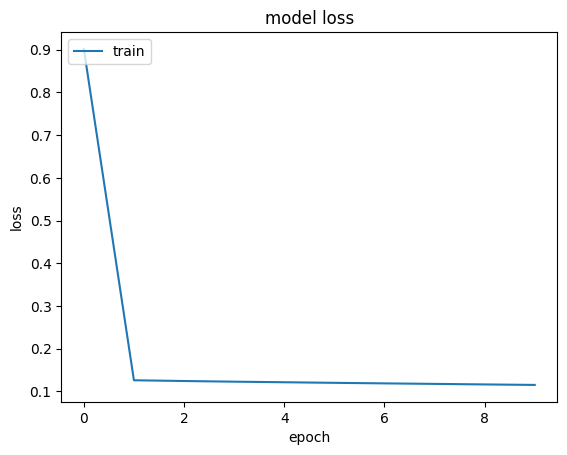

In [3]:
# ---------------------------------
# Model
# ---------------------------------
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
aiModel             = vaeTKAN(config=kanConfig)        

aiModel.compile(optimizer= Adam())
early_stop_loss     = 'loss'
early_stop_callback = EarlyStopping(monitor=early_stop_loss, min_delta = 1e-3, patience=5) 

history = aiModel.fit(
                        x           =   seqData,
                        y           =   seqData,
                        batch_size  =   kanConfig['batchSize'],
                        epochs      =   kanConfig['nEpoch'],
                        shuffle     =   True,
                        callbacks   =   [early_stop_callback],
                        verbose     =   1,
                        )


# ---------------------------------
# Save results
# ---------------------------------
plt.plot(history.history["loss"])
# plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train"],loc ="upper left")

# val_loss = history.history["val_loss"][-1]
# plt.savefig(kanConfig['dir'] + "/" +  "loss" + str(val_loss) + ".png")

(4908, 128, 17)


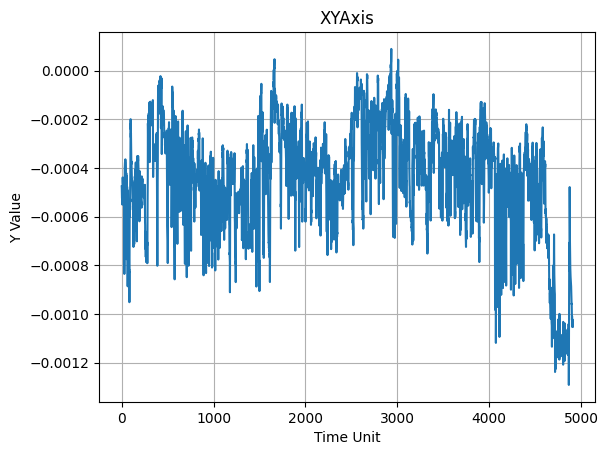

In [4]:
plot = MatPlot()

# ======================================
#  PREPROCESS THE DATA
# --------------------------------------
singleTraject   = trajectory["Válvula defectuosa"][0][preData.beauEfficiencyCr1 + preData.addEfficiencyCr1]
seqData,_         = preData.splitAndPadSequencesTensor([singleTraject,singleTraject],seqLength=kanConfig['seqLength'], overlap= kanConfig['overlap']) # Split data into each sequence

print(seqData.shape)
zLatent,_     = aiModel(seqData)
# print(zLatent.shape)
hi  = tf.reduce_mean(zLatent, axis=1)

plot.draw1D(hi)